# Fluxonium qubit simulation

This notebook runs the group's effective Fluxonium model using **scqubits**. It follows the same style as the repository's tunable-transmon and zero-pi notebooks: define a qubit object, calculate eigenenergies/eigenstates, inspect operators, and sweep external flux.

The baseline parameters are `EJ = 8.9 GHz`, `EC = 2.5 GHz`, `EL = 0.5 GHz`, `flux = 0.33 Phi_0`, and `cutoff = 110`. All energies are expressed as `E/h` in GHz, as expected by scqubits.

The implementation is an effective single-mode lumped-element model. It does not explicitly resolve the 100 junctions and their internal modes.

In [1]:
from pathlib import Path
import numpy as np
import scqubits as scq

from fluxonium_qubit import (
    BASIS_CUTOFF,
    EC_GHZ,
    EJ_GHZ,
    EL_GHZ,
    FLUX_BIAS_PHI0,
    NUMBER_OF_LEVELS,
    make_fluxonium,
    physical_parameter_estimates,
    run_simulation,
)

print("scqubits version:", scq.__version__)
print("Parameters:", {"EJ": EJ_GHZ, "EC": EC_GHZ, "EL": EL_GHZ,
                       "flux": FLUX_BIAS_PHI0, "cutoff": BASIS_CUTOFF})

scqubits version: 4.3.1
Parameters: {'EJ': 8.9, 'EC': 2.5, 'EL': 0.5, 'flux': 0.33, 'cutoff': 110}


## 1. Construct the baseline Fluxonium and calculate its eigensystem

The Hamiltonian is constructed by `scqubits.Fluxonium`. `eigensys` returns the eigenenergies and eigenvectors; subtracting the ground-state energy gives transition energies.

In [2]:
fluxonium = make_fluxonium(FLUX_BIAS_PHI0)
evals, evecs = fluxonium.eigensys(evals_count=NUMBER_OF_LEVELS)
relative_energies = evals - evals[0]

print("Energy levels (E/h, GHz):")
for index, energy in enumerate(evals):
    print(f"E{index} = {energy:.9f} GHz; E{index}-E0 = {relative_energies[index]:.9f} GHz")

f01 = evals[1] - evals[0]
f12 = evals[2] - evals[1]
print(f"\nf01 = {f01:.9f} GHz")
print(f"f12 = {f12:.9f} GHz")
print(f"Anharmonicity = {f12 - f01:.9f} GHz")

Energy levels (E/h, GHz):
E0 = -1.727377032 GHz; E0-E0 = 0.000000000 GHz
E1 = 1.343798996 GHz; E1-E0 = 3.071176028 GHz
E2 = 8.494484126 GHz; E2-E0 = 10.221861158 GHz
E3 = 12.134374294 GHz; E3-E0 = 13.861751326 GHz
E4 = 13.343294867 GHz; E4-E0 = 15.070671899 GHz
E5 = 17.704145646 GHz; E5-E0 = 19.431522678 GHz

f01 = 3.071176028 GHz
f12 = 7.150685131 GHz
Anharmonicity = 4.079509103 GHz


## 2. Convert effective circuit energies to SI estimates

These are conversions of the ideal effective circuit parameters. They are not separate electromagnetic geometry extractions.

In [3]:
physical = physical_parameter_estimates()
for name, value in physical.items():
    print(f"{name}: {value:.9g}")
print(f"\nEffective capacitance: {physical['effective_capacitance_F'] * 1e15:.6f} fF")
print(f"Central junction critical current: {physical['central_critical_current_A'] * 1e9:.6f} nA")
print(f"Superinductance: {physical['superinductance_H'] * 1e9:.6f} nH")

reduced_flux_quantum_Wb: 3.29105978e-16
central_critical_current_A: 1.79188554e-08
effective_capacitance_F: 7.74809173e-15
superinductance_H: 3.26923026e-07
array_junction_inductance_H: 3.26922139e-09
array_inductance_from_100_junctions_H: 3.26922139e-07
array_junction_EJ_GHz: 50.0001357

Effective capacitance: 7.748092 fF
Central junction critical current: 17.918855 nA
Superinductance: 326.923026 nH


## 3. Run the complete analysis and save plots/data

The next cell calculates the potential at zero and half flux, phase-basis wavefunctions at half flux, the energy spectrum over one flux quantum, charge/phase matrix elements, and a basis-cutoff check. CSV files, plots, and a summary are saved under `results/`.

FLUXONIUM QUBIT SIMULATION
scqubits version : 4.3.1
EJ, EC, EL       : 8.9, 2.5, 0.5 GHz
External flux    : 0.33 Phi_0
Basis cutoff     : 110
Output directory : C:\Users\expon\fluxonium_results

Energy levels (absolute, E/h in GHz):
  E0 = -1.727377032 GHz; E0-E0 =  0.000000000 GHz
  E1 =  1.343798996 GHz; E1-E0 =  3.071176028 GHz
  E2 =  8.494484126 GHz; E2-E0 =  10.221861158 GHz
  E3 =  12.134374294 GHz; E3-E0 =  13.861751326 GHz
  E4 =  13.343294867 GHz; E4-E0 =  15.070671899 GHz
  E5 =  17.704145646 GHz; E5-E0 =  19.431522678 GHz

f01           = 3.071176028 GHz
f12           = 7.150685131 GHz
Anharmonicity = 4.079509103 GHz
|<0|n|1>|     = 0.0566262318
|<0|phi|1>|   = 0.368759272

Physical estimates implied by the effective model:
  Effective capacitance : 7.748092 fF
  Central junction Ic   : 17.918855 nA
  Superinductance       : 326.923026 nH
  100-junction array L  : 326.922139 nH (using the reference array-junction Ic)


findfont: Failed to find font weight 500 for Arial, now using 400.
findfont: Failed to find font weight 500 for Arial, now using 400.


Spectral data:   0%|          | 0/101 [00:00<?, ?it/s]


Basis-cutoff check:
  cutoff       f01 (GHz)       f12 (GHz)       |delta f01| (GHz)
      80     3.071176027     7.150685131                 ---
      90     3.071176028     7.150685131        3.252012e-10
     100     3.071176028     7.150685131        5.236878e-11
     110     3.071176028     7.150685131        6.163958e-13
     120     3.071176028     7.150685131        6.661338e-14
     130     3.071176028     7.150685131        5.817569e-14

Saved results:
  cutoff_convergence.csv
  energy_levels.csv
  f01_vs_flux.png
  flux_spectrum.csv
  fluxonium_spectrum.png
  matrix_elements.csv
  matrix_elements.png
  phase_wavefunctions_half_flux.png
  potential_landscape.png
  simulation_summary.txt
  transition_frequencies.csv

Simulation completed.


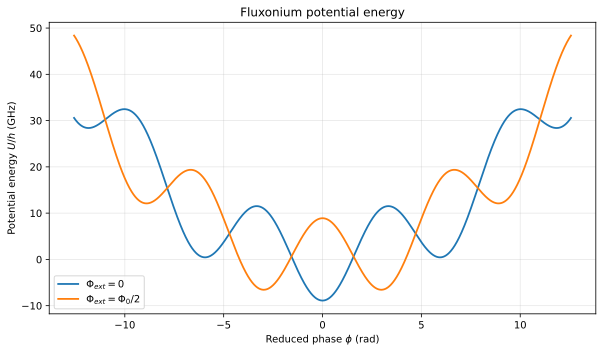

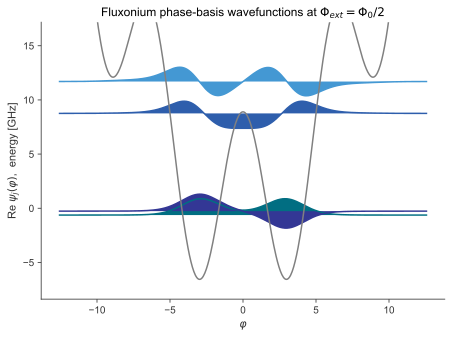

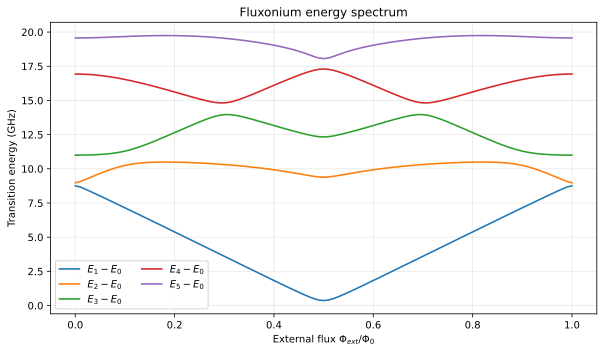

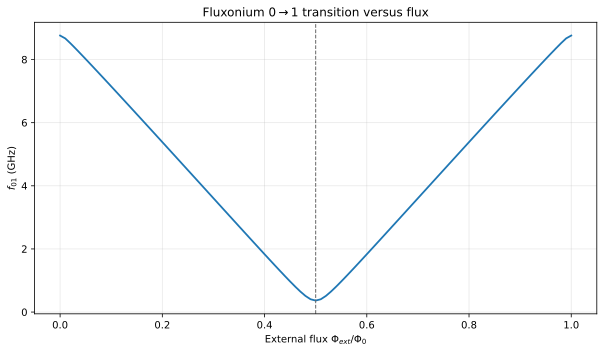

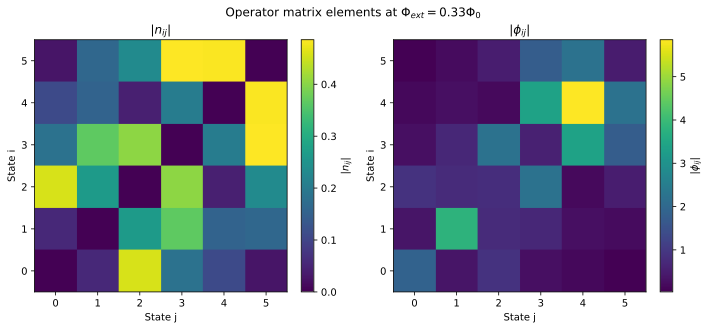


Saved to: C:\Users\expon\fluxonium_results


In [4]:
results = run_simulation(
    show_plots=True,
    output_dir=Path.home() / "fluxonium_results",
)
print("\nSaved to:", results["output_dir"].resolve())

## 4. Inspect selected outputs

The full numerical results are also written to CSV files for reproducibility and plotting outside the notebook.

In [5]:
print("f01 at baseline flux (GHz):", results["f01_GHz"])
print("f12 at baseline flux (GHz):", results["f12_GHz"])
print("Anharmonicity (GHz):", results["anharmonicity_GHz"])
print("|n01|:", abs(results["n_operator"][0, 1]))
print("|phi01|:", abs(results["phi_operator"][0, 1]))

f01 at baseline flux (GHz): 3.0711760275833395
f12 at baseline flux (GHz): 7.150685130806768
Anharmonicity (GHz): 4.079509103223429
|n01|: 0.05662623177429187
|phi01|: 0.3687592717949952


## References

- [scqubits Fluxonium guide](https://scqubits.readthedocs.io/en/latest/guide/qubits/fluxonium.html)
- [scqubits Fluxonium API](https://scqubits.readthedocs.io/en/latest/api-doc/_autosummary/scqubits.core.fluxonium.Fluxonium.html)
- Manucharyan et al., *Science* 326, 113–116 (2009), DOI: 10.1126/science.1175552

**Model limitation:** This notebook implements the effective single-mode Fluxonium Hamiltonian. It does not model the explicit array modes, parasitic capacitances, junction disorder, losses, or a microwave readout/control environment.